# Ji et al. 2020 — Cutaneous Squamous Cell Carcinoma (cSCC)
## 01 · Preprocessing, integration & manifold scoping

Malignant cells (10x, UMI counts; `load.py` normalizes + `log1p`s). Goal: an integrated, continuous manifold on which to fit the cell-state trajectory. **Gate 1** is judged *visually* on the regenerated embedding across an integration sweep — is the malignant structure sample-mixed and continuous? A proliferating (cycling) compartment is a trajectory confound (03_eval lobe-identity rule): it is identified here and **scoped out** to the developmental compartment on which the trajectory is fit, then judged visually. The geometry itself (branching vs non-branching) is not assumed — it is read off the signature geography in 02–03.

In [1]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Ji2020_Skin-3  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Skin
dset = re.sub(r'-\d+$', '', name)                       # strip -N suffix -> input folder key
pth  = os.path.join(*([os.pardir]*4))                 # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Ji2020_Skin-3 | category: Skin


### Load malignant cells + published metadata
`load.py` sets `celltype='Malignant'`. Ji et al.'s published per-cell subtypes (`cell_subtype_level1`: Basal / Diff / Cyc keratinocytes, the EMT-like **TSK** leading-edge), cell-cycle phase and meta-program calls come through in `obs` and anchor the annotation.

In [3]:
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| Xmax %.2f (counts->norm, log1p)' % adata.X.max())
print('published subtypes:', adata.obs.cell_subtype_level1.value_counts().to_dict())
print('cell-cycle phase :', adata.obs.cell_cycle_phase.value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Ji2020_Skin
Done.
malignant: (10598, 32738) | Xmax 8.12 (counts->norm, log1p)
published subtypes: {'Keratinocyte': 5715, 'Tumor_KC_Diff': 2370, 'Tumor_KC_Basal': 1395, 'Tumor_KC_Cyc': 794, 'TSK': 324}
cell-cycle phase : {'Not cycling': 6836, 'G1/S': 1678, 'G2/M': 1504, 'Intermediate': 560}


### Sample threshold — read the per-sample count gap
Sort per-sample malignant counts and look for a clean multiplicative gap. The counts fall 1130…268 then drop to 40/27 — a **6.7x gap at 268->40**, well clear of the >=100 floor. Keep samples above it (8/10).

In [4]:
n = adata.obs['sample'].value_counts()
ratios = (n.values[:-1] / n.values[1:]).round(2)
print('descending counts:', dict(zip(n.index, n.values.astype(int))))
print('adjacent ratios  :', ratios.tolist())
keep = n.index[n >= 100]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print('kept %d/%d samples (>=100) -> %d cells' % (len(keep), n.size, adata.n_obs))

descending counts: {'P4': np.int64(4216), 'P8': np.int64(1472), 'P10': np.int64(1130), 'P1': np.int64(1064), 'P7': np.int64(1012), 'P6': np.int64(729), 'P2': np.int64(640), 'P9': np.int64(268), 'P5': np.int64(40), 'P3': np.int64(27)}
adjacent ratios  : [2.86, 1.3, 1.06, 1.05, 1.39, 1.14, 2.39, 6.7, 1.48]
kept 8/10 samples (>=100) -> 10531 cells


### Gene filter -> overdispersed selection -> PCA

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('cum var @ n_pcs=20: %.3f  @30: %.3f' % (vr[:20].sum(), vr[:30].sum()))

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1443 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1443
cum var @ n_pcs=20: 0.438  @30: 0.472


### Integration strength — Harmony `theta` swept and judged on the embedding
cSCC malignant cells carry strong patient-specific CNVs, so integration must mix patients without collapsing biology. Per the binding Gate-1 lesson (Kürten §1) the choice is made **on the regenerated embedding across the sweep**, not a scalar alone. We sweep `theta`, record the same-sample neighbour fraction (lower = better mixing), and re-embed at each `theta` to inspect mixing directly. `n_pcs=20`, `spread=1.3` follow the 10x precedents (Kürten/Sun/Lee), not the Puram SmartSeq2 anchor. No `sc.pp.scale` (absent from the reference protocol; it fragments the manifold).

In [6]:
NPC = 20
def same_sample_frac(rep, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:, 1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]] == s[i]).mean() for i in range(len(s))]))
base = same_sample_frac(adata.obsm['X_pca'][:, :NPC]); reps = {}; ssf = {}
for th in [0, 2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    reps[th] = adata.obsm['X_pca_harmony'].copy()
    ssf[th] = same_sample_frac(adata.obsm['X_pca_harmony'][:, :NPC])
print('pre-Harmony same-sample frac: %.3f' % base)
print('theta sweep (same-sample frac):', {k: round(v, 3) for k, v in ssf.items()})

2026-08-10 18:05:07,470 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-10 18:05:08,734 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-10 18:05:08,787 - harmonypy - INFO - Iteration 1 of 30
2026-08-10 18:05:10,926 - harmonypy - INFO - Iteration 2 of 30
2026-08-10 18:05:13,063 - harmonypy - INFO - Iteration 3 of 30
2026-08-10 18:05:15,206 - harmonypy - INFO - Converged after 3 iterations
2026-08-10 18:05:15,472 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-10 18:05:16,765 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-10 18:05:16,808 - harmonypy - INFO - Iteration 1 of 30
2026-08-10 18:05:18,960 - harmonypy - INFO - Iteration 2 of 30
2026-08-10 18:05:21,140 - harmonypy - INFO - Iteration 3 of 30
2026-08-10 18:05:23,295 - harmonypy - INFO - Iteration 4 of 30
2026-08-10 18:05:25,444 - harmonypy - INFO - Iteration 5 of 30
2026-08-10 18:05:27,593 - harmonypy - INFO - Converged after

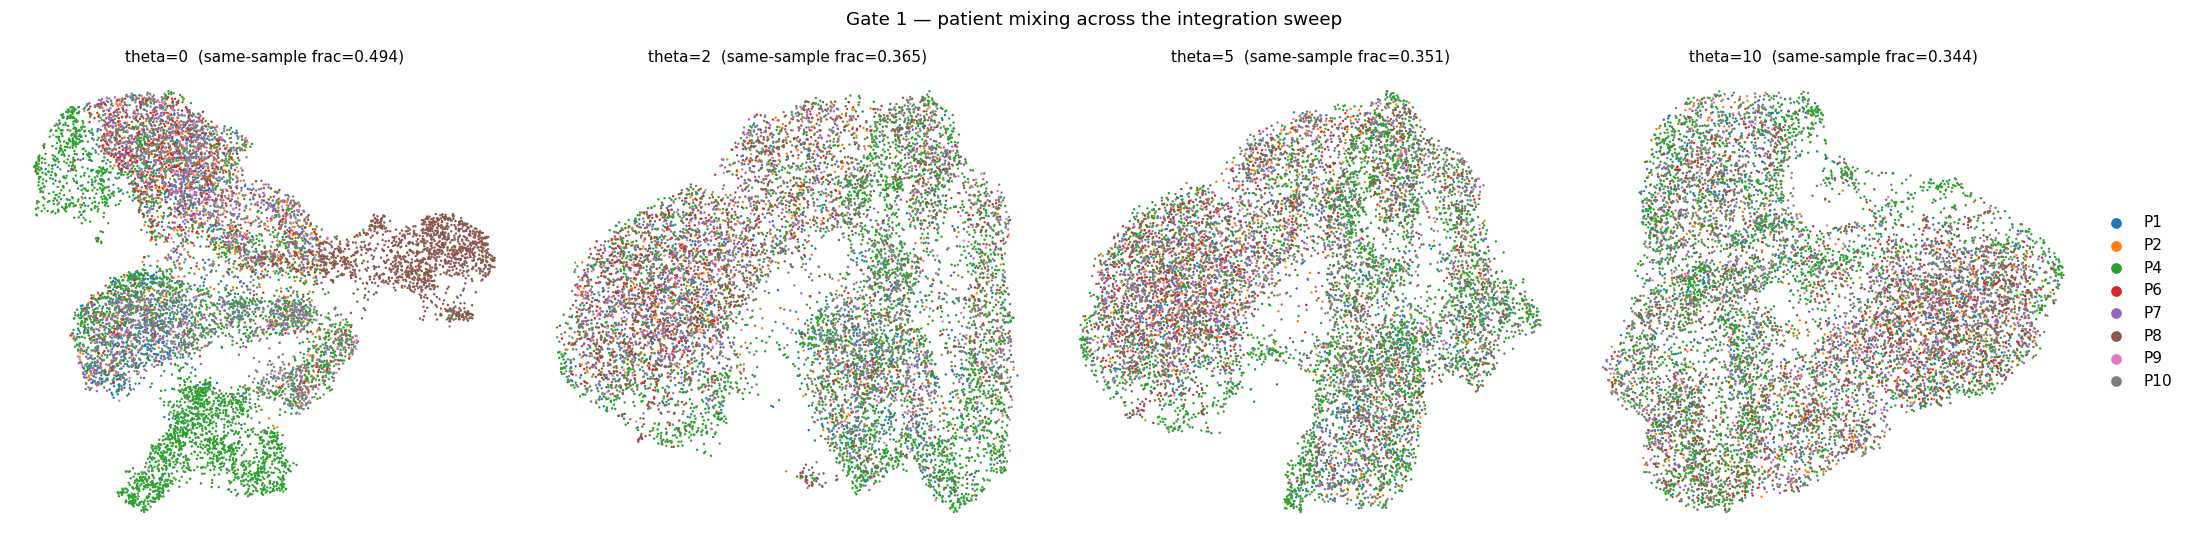

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, th in zip(axs, [0, 2, 5, 10]):
    tmp = adata.copy(); tmp.obsm['X_pca_harmony'] = reps[th]
    sc.pp.neighbors(tmp, n_pcs=NPC, use_rep='X_pca_harmony', random_state=SEED)
    sc.tl.umap(tmp, spread=1.3, random_state=SEED)
    sc.pl.umap(tmp, color='sample', ax=ax, show=False, size=10, frameon=False,
               legend_loc='right margin' if th == 10 else None)
    ax.set_title('theta=%d  (same-sample frac=%.3f)' % (th, ssf[th]), size=10)
fig.suptitle('Gate 1 — patient mixing across the integration sweep', size=12); fig.tight_layout(); plt.show()

**Read of the sweep.** At `theta=0` patients own distinct lobes (P4 green, P8 brown); by `theta=2` patients are interspersed and `theta=5` reads as one integrated continuum, with only cosmetic change to `theta=10` (which begins to blob the structure). We adopt **`theta=5`** — clean visual mixing while structure is preserved.

In [8]:
sce.pp.harmony_integrate(adata, 'sample', theta=5, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPC, n_neighbors=30, use_rep='X_pca_harmony', random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
sc.tl.leiden(adata, resolution=0.6, random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
print('adopted theta=5 | leiden clusters:', adata.obs.leiden.nunique())

adopted theta=5 | leiden clusters: 7


### Gate 1 (part 1) — mixing & continuity on the embedding
Samples intermix across one connected body (no per-patient archipelago); one connected kNN component. The **cycling compartment is visually obvious** as a coherent lobe (G2/M + G1/S).

kNN connected components: 1 | samples intermixed: 8


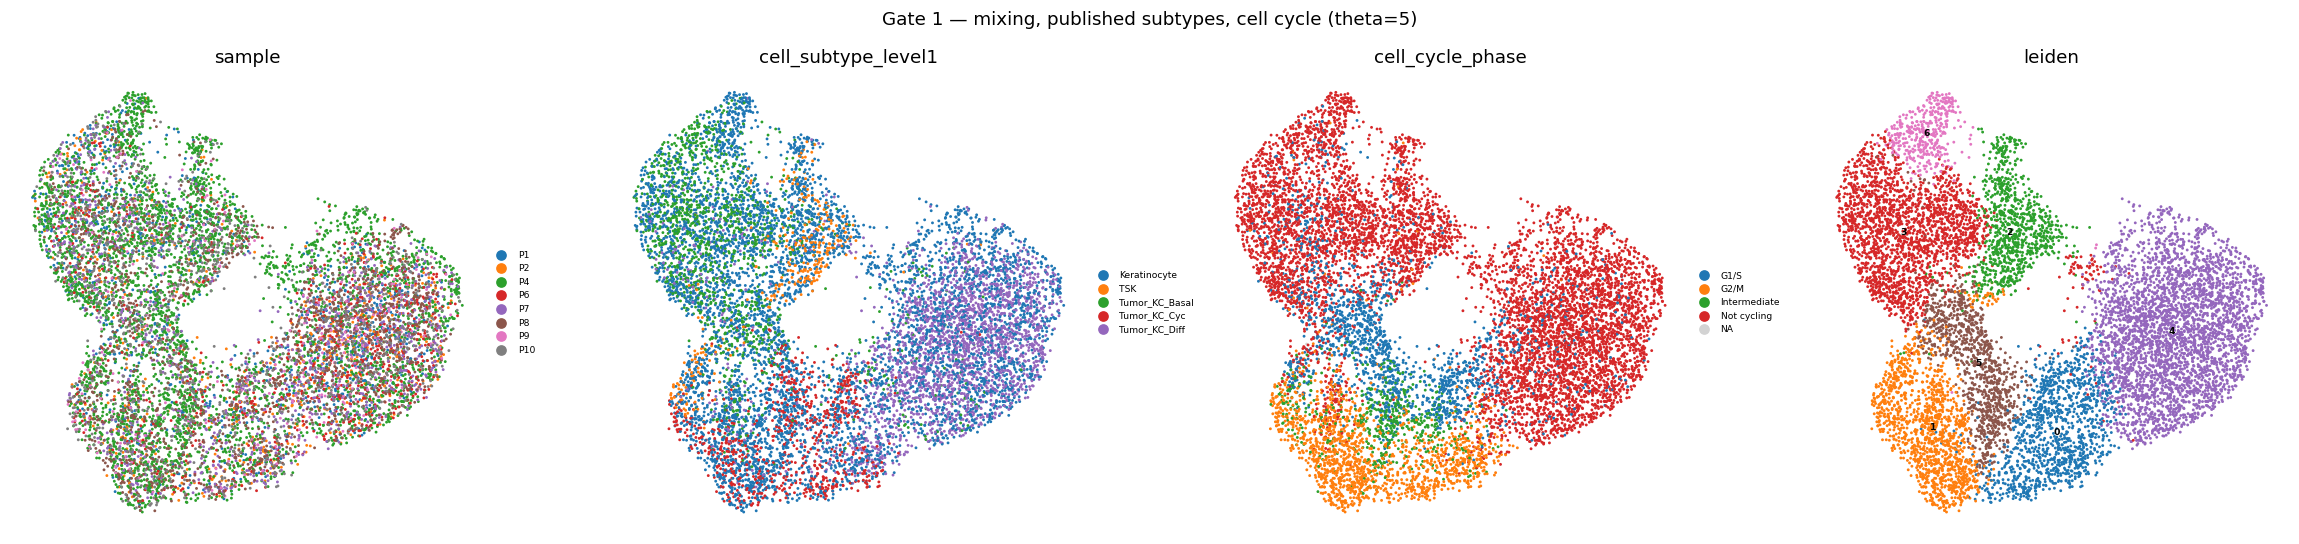

In [9]:
adata.obs['cycling'] = adata.obs.cell_cycle_phase.isin(['G1/S', 'G2/M', 'Intermediate'])
from scipy.sparse.csgraph import connected_components
ncomp, _ = connected_components(adata.obsp['connectivities'], directed=False)
fig, axs = plt.subplots(1, 4, figsize=(21, 5))
for ax, c in zip(axs, ['sample', 'cell_subtype_level1', 'cell_cycle_phase', 'leiden']):
    sc.pl.umap(adata, color=c, ax=ax, show=False, size=14, frameon=False,
               legend_loc='on data' if c == 'leiden' else 'right margin', legend_fontsize=6)
    ax.set_title(c)
fig.suptitle('Gate 1 — mixing, published subtypes, cell cycle (theta=5)', size=12); fig.tight_layout(); plt.show()
print('kNN connected components:', ncomp, '| samples intermixed:', adata.obs['sample'].nunique())

**Gate 1 = GO.** Patients are thoroughly interspersed across one continuous connected manifold. A distinct cycling lobe (Tumor_KC_Cyc / G2/M-G1/S) is present and is scoped out below so it does not confound the trajectory.

### Score the embryonic modules + graph-smooth
`score_genes` with the `union` control pool (reference protocol). Per the binding directive, geography and rooting are read off **graph-smoothed** scores (raw per-cell scores are noise-dominated at 10x depth; Chen §attempt-3 lesson) — smoothed via kNN-connectivity averaging.

In [10]:
fd = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates().dropna()
      for f in sorted(glob.glob(os.path.join(FEAT, '*.csv')))}
gref = fd['union'][fd['union'].isin(adata.var_names)]
for src, s in fd.items():
    if src == 'union': continue
    g = s[s.isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=src, ctrl_as_ref=False,
                      gene_pool=list(gref), random_state=1234)
    print('%s: %d/%d genes recovered' % (src, g.size, gref.size))
adata.obs['Gast'] = adata.obs.GSE162534; adata.obs['pSom'] = adata.obs.GSE229103; adata.obs['Crest'] = adata.obs.rRNAModifications
A = adata.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg == 0] = 1
for k in ['Gast', 'pSom', 'Crest']: adata.obs[k+'_sm'] = (A @ adata.obs[k].values) / deg

GSE162534: 76/224 genes recovered
GSE229103: 88/224 genes recovered
rRNAModifications: 101/224 genes recovered


### Identify & scope out the cycling lobe
Per-Leiden cycling fraction: the cycling lobe is the set of clusters that are **majority cycling (>50%)**. These proliferating cells confound pseudotime; removing them lets the developmental fork resolve (03_eval lobe-identity rule). Critically, in this dataset the cycling cells are **Gast-low** (Gast peaks in the differentiated wing), so cell cycle is orthogonal to the embryonic modules — this removes a confound, not developmental signal.

In [11]:
cyc_frac = adata.obs.groupby('leiden', observed=True)['cycling'].mean().sort_values(ascending=False)
gast_by = adata.obs.groupby('leiden', observed=True)['Gast_sm'].mean()
print('per-leiden cycling fraction | mean Gast_sm:')
for lz in cyc_frac.index: print('  %2s  cyc=%.3f  Gast_sm=%+.3f' % (lz, cyc_frac[lz], gast_by[lz]))
cyc_lobes = cyc_frac.index[cyc_frac > 0.5].tolist()
print('cycling-lobe clusters (>50% cycling):', cyc_lobes)
adata.obs['compartment'] = np.where(adata.obs.leiden.isin(cyc_lobes), 'Cycling', 'Developmental')
print(adata.obs.compartment.value_counts().to_dict())

per-leiden cycling fraction | mean Gast_sm:
   5  cyc=0.934  Gast_sm=-0.058
   1  cyc=0.859  Gast_sm=-0.077
   0  cyc=0.826  Gast_sm=-0.039
   3  cyc=0.116  Gast_sm=-0.018
   2  cyc=0.095  Gast_sm=-0.053
   6  cyc=0.078  Gast_sm=-0.054
   4  cyc=0.060  Gast_sm=-0.006
cycling-lobe clusters (>50% cycling): ['5', '1', '0']
{'Developmental': 6897, 'Cycling': 3634}


### Re-embed the developmental compartment
Re-embed the developmental (non-cycling) compartment on the integrated PCs so the embryonic-module geography is read without the proliferation confound. The re-embedding is checked for folds in 02 (node self-approach ratio; the Kürten §4 fold risk) before any continuity claim is made. Confirm **visually** here that samples still intermix and the smoothed modules vary smoothly across it.

scoped developmental fork: 6897 cells (removed 3634 cycling)


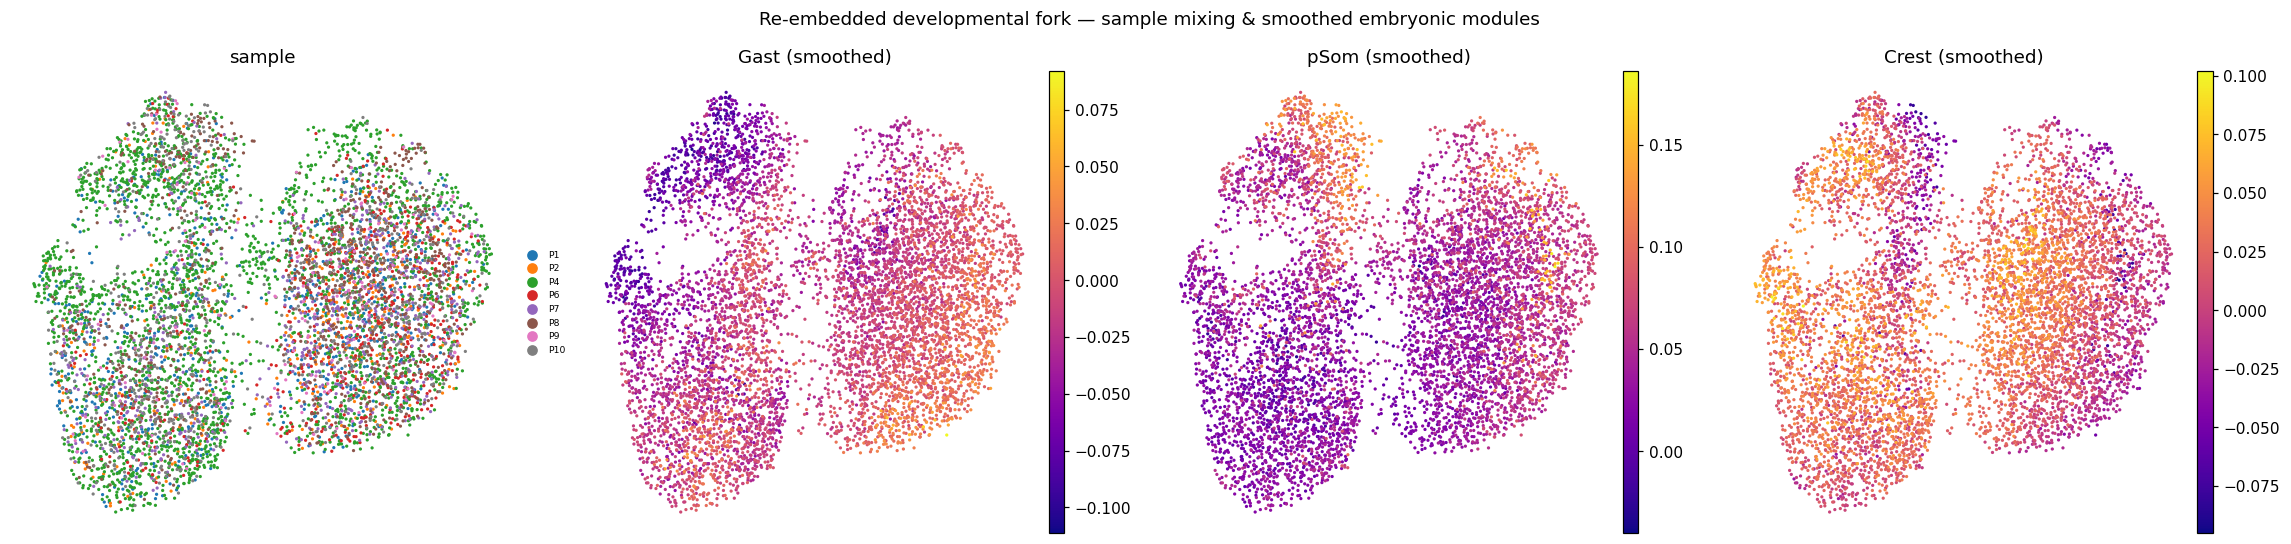

In [12]:
fork = adata[adata.obs.compartment == 'Developmental'].copy()
sc.pp.neighbors(fork, n_pcs=NPC, n_neighbors=30, use_rep='X_pca_harmony', random_state=SEED)
sc.tl.umap(fork, min_dist=0.5, spread=1.0, random_state=SEED)
A = fork.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg == 0] = 1
for k in ['Gast', 'pSom', 'Crest']: fork.obs[k+'_sm'] = (A @ fork.obs[k].values) / deg
print('scoped developmental fork:', fork.n_obs, 'cells (removed', adata.n_obs - fork.n_obs, 'cycling)')
fig, axs = plt.subplots(1, 4, figsize=(21, 5))
for ax, c in zip(axs, ['sample', 'Gast_sm', 'pSom_sm', 'Crest_sm']):
    sc.pl.umap(fork, color=c, ax=ax, show=False, size=18, frameon=False,
               cmap=None if c == 'sample' else 'plasma', legend_fontsize=6)
    ax.set_title(c.replace('_sm', ' (smoothed)'))
fig.suptitle('Re-embedded developmental fork — sample mixing & smoothed embryonic modules', size=12)
fig.tight_layout(); plt.show()

### Annotate subtypes — data markers + Ji 2020 published states
Cluster the compartment (Leiden res=0.5) and assign each cluster a role from **both** its data-derived module/marker profile and the Ji-2020 published subtypes (Ji et al., 2020, *Cell* 182:497). The rule is derived and shown, not asserted:
- **Mixed** — the embryonic-module convergence zone: the cluster with maximal Gast+pSom co-expression (Puram's "Mixed" analog; the trajectory origin).
- **TSK/EMT** — the leading-edge state: highest pSom with the Ji TSK markers `MMP10`/`PTHLH`/`LAMC2`.
- **Differentiated** — the differentiation state: highest cornified-envelope keratins `KRT1`/`KRT10`.
- **Basal** — the progenitor body: `TP63`-high, Basal-subtype-enriched, low module scores.
Marker means and the published-subtype composition per cluster are printed so the mapping is auditable.

       n   Gast   pSom  Crest  joint   KRT1  KRT10  MMP10  PTHLH  LAMC2   TP63  basal_frac
lz                                                                                        
0   1457 -0.018  0.022  0.024  0.004  0.460  1.064  0.015  0.120  0.116  0.779       0.406
1    842 -0.055  0.076  0.014  0.021  0.349  0.924  0.433  0.630  0.826  0.692       0.075
2    722 -0.018  0.042  0.017  0.024  0.746  1.339  0.027  0.115  0.193  0.827       0.277
3    431 -0.052  0.027  0.037 -0.025  0.352  0.789  0.011  0.044  0.223  0.636       0.399
4   2034 -0.007  0.054  0.015  0.047  2.553  2.384  0.009  0.086  0.049  0.424       0.006
5   1411 -0.004  0.037  0.014  0.033  2.916  2.561  0.002  0.018  0.052  0.466       0.041
roles -> hub(Mixed)=4  TSK/EMT=1  Differentiated=5
celltype: {'Basal': 2610, 'Mixed': 2034, 'Differentiated': 1411, 'TSK/EMT': 842}


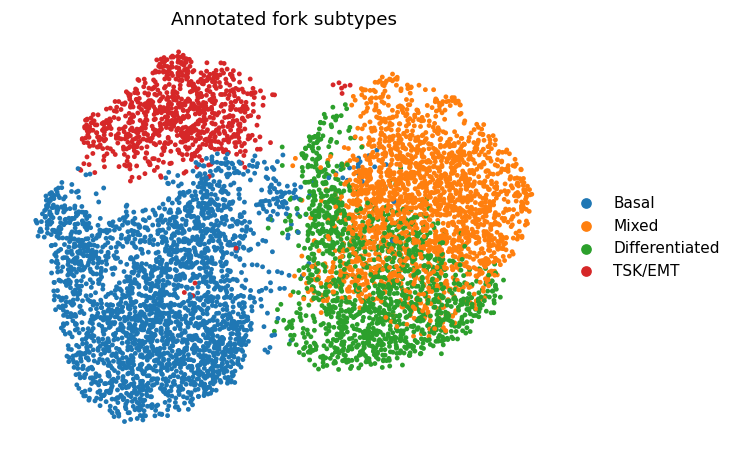

In [13]:
sc.tl.leiden(fork, resolution=0.5, random_state=SEED, key_added='lz', flavor='igraph', n_iterations=2, directed=False)
def gmean(g): 
    v = np.asarray(fork[:, g].X.todense()).ravel()
    return pd.Series(v, index=fork.obs_names).groupby(fork.obs.lz, observed=True).mean()
prof = fork.obs.groupby('lz', observed=True).agg(n=('lz','size'), Gast=('Gast_sm','mean'),
        pSom=('pSom_sm','mean'), Crest=('Crest_sm','mean'))
prof['joint'] = prof.Gast + prof.pSom
for g in ['KRT1','KRT10','MMP10','PTHLH','LAMC2','TP63']: prof[g] = gmean(g)
prof['basal_frac'] = fork.obs.groupby('lz', observed=True).apply(
    lambda s: (s.cell_subtype_level1 == 'Tumor_KC_Basal').mean())
print(prof.round(3).to_string())
hub = prof.joint.idxmax()
tsk = prof.drop(hub)[['pSom']].join(prof[['MMP10','LAMC2']]).assign(
        s=lambda d: d.pSom.rank()+d.MMP10.rank()+d.LAMC2.rank()).s.idxmax()
diff = prof.drop([hub, tsk]).assign(s=lambda d: d.KRT1.rank()+d.KRT10.rank()).s.idxmax()
lab = {}
for lz in prof.index:
    lab[lz] = 'Mixed' if lz==hub else ('TSK/EMT' if lz==tsk else ('Differentiated' if lz==diff else 'Basal'))
fork.obs['celltype'] = pd.Categorical(fork.obs.lz.map(lab),
        categories=['Basal','Mixed','Differentiated','TSK/EMT'], ordered=True)
print('roles -> hub(Mixed)=%s  TSK/EMT=%s  Differentiated=%s' % (hub, tsk, diff))
print('celltype:', fork.obs.celltype.value_counts().to_dict())
sc.pl.umap(fork, color='celltype', size=40, title='Annotated fork subtypes', frameon=False); plt.show()

### Save processed manifold (scoped, re-embedded, annotated)

In [14]:
fork.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', fork.shape)

saved processed.h5ad (6897, 21042)


### `samples.pdf` — sample integration on the analysis manifold (Gate 1 evidence)
Reference layout: single sample-coloured manifold UMAP, external legend, dataset citation.

saved samples.pdf


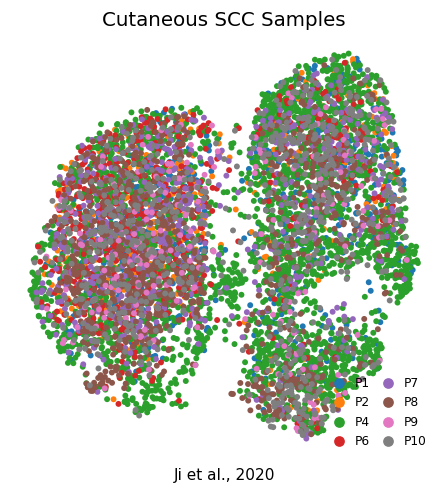

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(fork, color='sample', size=60, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='lower right', columnspacing=.5, handletextpad=.25, fontsize=8)
ax.set_title('Cutaneous SCC Samples', size=13)
ax.text(.5, -.05, 'Ji et al., 2020', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf')